# 02 - discretizeFPKM

Port of `scripts/rFASTCORMICS/discretizeFPKM.m`, checked cell by cell against MATLAB's output.

What the MATLAB does, per sample:

1. `signal = log2(fpkm)`, `Inf -> -1e6`
2. `ksdensity` on the finite part -> 100-point kernel density `(f, xi)`
3. method 1: take the peak of `f[50:100]` (1-based), mirror the right flank around it to build
   a `hybrid_curve`, `rest = f - hybrid` (values < 1e-4 zeroed), fit a `gauss1` to each
4. method 2: same but with the global peak
5. pick method 1 if `ue_r < 0`, otherwise method 2 (the left-skew fix added in v2)
6. `zFPKM = (signal - mu1)/sigma1`; `z >= 0` -> 1, `z <= ue` -> -1, else 0

Two things that had to be matched exactly:

- **ksdensity defaults**: normal kernel, bandwidth `median(|x-median(x)|)/0.6745 * (4/3n)^(1/5)`,
  grid `linspace(min-3h, max+3h, 100)`.
- **gauss1 fits**: `createFitR.m` / `createFitL.m` hard-code the `StartPoint` and
  `Lower = [-Inf -Inf 0]`. Same starts are used here with `scipy.optimize.least_squares`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rfastcormics_v2 as rf

exp = np.load("data/expression.npz", allow_pickle=True)
fpkm, rownames, colnames = exp["fpkm"], exp["rownames"], exp["colnames"]
disc_matlab = exp["discretized_matlab"]
fpkm.shape, colnames.size

((23368, 25), 25)

In [2]:
disc_py, scaled, details = rf.discretize_fpkm(fpkm, colnames, verbose=False,
                                             return_details=True)
disc_py.shape, dict(zip(*np.unique(disc_py, return_counts=True)))

((23368, 25),
 {np.float64(-1.0): np.int64(183715),
  np.float64(0.0): np.int64(236870),
  np.float64(1.0): np.int64(163615)})

In [3]:
import pandas as pd
pd.DataFrame(details)[["sample", "mu1", "mu2", "sigma1", "ue", "method"]].head(10)

,sample,mu1,mu2,sigma1,ue,method
0,TCGA_A2_A3KC_01A_11R_A213_07,3.512721,-1.873537,1.642585,-3.000000,1
1,TCGA_A7_A6VW_01A_21R_A33J_07,2.914286,-3.414403,2.422215,-2.612769,1
2,TCGA_A8_A09B_01A_11R_A00Z_07,3.548185,-2.068363,1.722138,-3.000000,1
3,TCGA_A8_A0A1_01A_11R_A00Z_07,3.367346,-2.213544,1.720320,-3.000000,1
4,TCGA_A8_A0AB_01A_11R_A034_07,3.665187,-2.467640,1.712045,-3.000000,1
5,TCGA_AC_A3OD_01A_11R_A21T_07,3.948964,-0.631573,1.312127,-3.000000,1
6,TCGA_AC_A3QQ_01A_11R_A22K_07,3.485811,-1.960737,1.519583,-3.000000,1
7,TCGA_AC_A3TN_01A_11R_A22K_07,2.924377,-3.626213,2.435707,-2.689400,1
8,TCGA_AO_A03U_01B_21R_A10J_07,3.009911,-3.149547,1.863156,-3.000000,1
9,TCGA_AO_A0JE_01A_11R_A056_07,3.004688,-3.044256,2.029108,-2.981085,1


## Against MATLAB

In [4]:
mism = disc_py != disc_matlab
print("cells:", disc_py.size)
print("mismatches:", int(mism.sum()), "->", "%.6f%% agreement" % (100 * (1 - mism.mean())))
print("per sample:", mism.sum(axis=0))

cells: 584200
mismatches: 14 -> 99.997604% agreement
per sample: [0 0 0 0 0 3 0 1 0 1 0 1 0 0 0 1 0 1 0 0 1 0 1 1 3]


In [5]:
ii, jj = np.where(mism)
for i, j in list(zip(ii, jj))[:10]:
    z, ue = scaled[i, j], details[j]["ue"]
    print(f"{rownames[i]:<12} sample={j:<3} z={z:.8f} ue={ue:.8f} "
          f"|z-ue|={abs(z-ue):.2e}  py={disc_py[i,j]:+.0f} matlab={disc_matlab[i,j]:+.0f}")

ADRA1D       sample=24  z=-2.99508409 ue=-2.99488079 |z-ue|=2.03e-04  py=-1 matlab=+0
CD1A         sample=24  z=-2.99517698 ue=-2.99488079 |z-ue|=2.96e-04  py=-1 matlab=+0
CHRNA6       sample=23  z=-2.50414271 ue=-2.50419784 |z-ue|=5.51e-05  py=+0 matlab=-1
CORO7        sample=5   z=-3.00129504 ue=-3.00000000 |z-ue|=1.30e-03  py=-1 matlab=+0
DLGAP1       sample=11  z=-3.00014552 ue=-3.00000000 |z-ue|=1.46e-04  py=-1 matlab=+0
LOC100506035 sample=7   z=-2.68926323 ue=-2.68940021 |z-ue|=1.37e-04  py=+0 matlab=-1
LOC439990    sample=17  z=-3.00023551 ue=-3.00000000 |z-ue|=2.36e-04  py=-1 matlab=+0
LRRC36       sample=5   z=-3.00015794 ue=-3.00000000 |z-ue|=1.58e-04  py=-1 matlab=+0
NIPAL4       sample=20  z=-3.00032819 ue=-3.00000000 |z-ue|=3.28e-04  py=-1 matlab=+0
PPARGC1A     sample=15  z=-2.81805202 ue=-2.81782245 |z-ue|=2.30e-04  py=-1 matlab=+0


All of them sit right on the `ue` threshold. MATLAB's `fit` stops at `TolFun = 1e-6`
and lands on a slightly different point than scipy does; tightening or loosening scipy's
tolerance doesn't change the count, so the fit is converged and MATLAB's isn't quite.

What matters is whether this survives the consensus step (>= 90% of samples):

In [6]:
for name, val in [("expressed (1)", 1), ("not expressed (-1)", -1)]:
    a = (disc_py == val).sum(1) >= 0.9 * disc_py.shape[1]
    b = (disc_matlab == val).sum(1) >= 0.9 * disc_matlab.shape[1]
    print(f"{name:<20} python={a.sum():5d}  matlab={b.sum():5d}  identical={bool((a==b).all())}")

expressed (1)        python= 3751  matlab= 3751  identical=True
not expressed (-1)   python= 4873  matlab= 4873  identical=True


Identical, so the flipped cells never reach the core set. (Notebook 03 checks the same
thing one level further down, at the reaction mapping matrix.)

## One sample, plotted

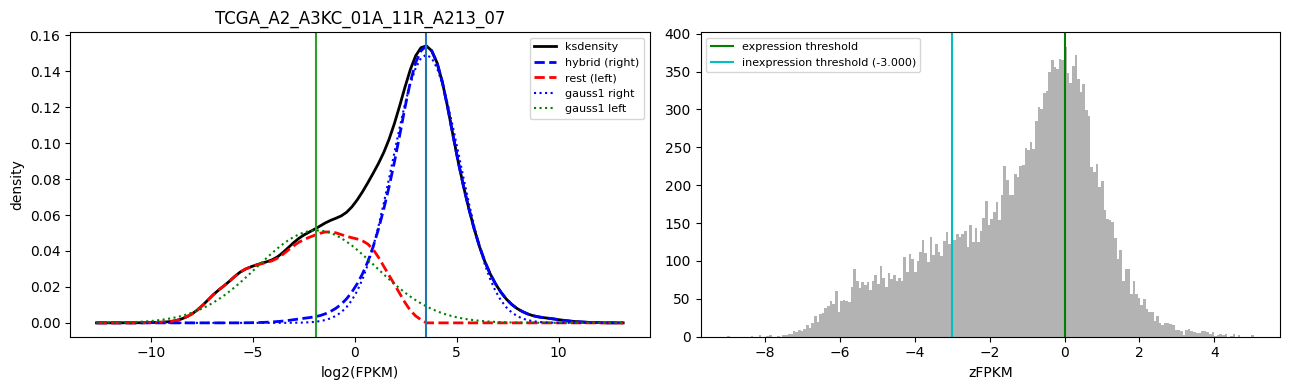

In [7]:
j = 0
signal = np.log2(fpkm[:, j], where=fpkm[:, j] > 0,
                 out=np.full(fpkm.shape[0], -np.inf))
s = signal[np.isfinite(signal)]
prob, xi, bw = rf.ksdensity(s)

peak_r = int(np.flatnonzero(prob == prob[49:100].max())[0])
hyb_r, rest_r = rf._hybrid_and_rest(prob, peak_r)
a1, b1, c1 = rf.fit_gauss1(xi, hyb_r, rf._START_R)
a2, b2, c2 = rf.fit_gauss1(xi, rest_r, rf._START_L)
g = lambda x, a, b, c: a * np.exp(-(((x - b) / c) ** 2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(xi, prob, "k", lw=2, label="ksdensity")
ax[0].plot(xi, hyb_r, "b--", lw=2, label="hybrid (right)")
ax[0].plot(xi, rest_r, "r--", lw=2, label="rest (left)")
ax[0].plot(xi, g(xi, a1, b1, c1), "b:", label="gauss1 right")
ax[0].plot(xi, g(xi, a2, b2, c2), "g:", label="gauss1 left")
ax[0].axvline(details[j]["mu1"], color="C0"); ax[0].axvline(details[j]["mu2"], color="C2")
ax[0].set_xlabel("log2(FPKM)"); ax[0].set_ylabel("density")
ax[0].set_title(str(colnames[j])); ax[0].legend(fontsize=8)

z = scaled[:, j]
ax[1].hist(z[np.isfinite(z) & (z > -20)], bins=200, color="0.7")
ax[1].axvline(0, color="g", label="expression threshold")
ax[1].axvline(details[j]["ue"], color="c",
              label=f"inexpression threshold ({details[j]['ue']:.3f})")
ax[1].set_xlabel("zFPKM"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
np.save("data/discretized_python.npy", disc_py)